In [17]:
# Import necessary libraries
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

In [13]:
# 1. Simulate Cyber Risk Data
# ------------------------------
# For demo purposes, we create a synthetic dataset.
# Features might include:
# - number_of_incidents: Count of cybersecurity incidents in the past year.
# - vulnerability_score: A score indicating the vulnerability of the systems.
# - intrusion_attempts: Count of detected intrusion attempts.
# - audit_score: A score from a recent security audit (higher is better).
# - employee_training_score: A score reflecting employee cybersecurity training.

# Create a DataFrame with 500 samples
np.random.seed(42)
data = {
    'number_of_incidents': np.random.poisson(lam=2, size=500),
    'vulnerability_score': np.random.uniform(0, 10, size=500),
    'intrusion_attempts': np.random.poisson(lam=5, size=500),
    'audit_score': np.random.uniform(0, 100, size=500),
    'employee_training_score': np.random.uniform(0, 100, size=500)
}
df = pd.DataFrame(data)

# Define risk levels based on a simple rule:
# Let's say a higher vulnerability score and higher number of intrusion attempts increase risk,
# whereas a higher audit_score and training_score reduce risk.
# We create a risk score, then define risk categories.
df['risk_score'] = (df['vulnerability_score'] * 0.4 + 
                    df['number_of_incidents'] * 1.5 + 
                    df['intrusion_attempts'] * 1.0 - 
                    df['audit_score'] * 0.05 - 
                    df['employee_training_score'] * 0.05)

# Based on risk_score, label risk categories:
# Low risk if risk_score < 5, Medium if between 5 and 10, High if > 10.
def categorize_risk(score):
    if score < 5:
        return 'Low'
    elif score < 10:
        return 'Medium'
    else:
        return 'High'

df['risk_category'] = df['risk_score'].apply(categorize_risk)

# For our model, we want numerical labels
risk_mapping = {'Low': 0, 'Medium': 1, 'High': 2}
df['risk_label'] = df['risk_category'].map(risk_mapping)

print(df.head())

   number_of_incidents  vulnerability_score  intrusion_attempts  audit_score  \
0                    4             3.961727                   7     3.926505   
1                    1             6.954672                   4    97.728382   
2                    3             3.885581                   4    24.235370   
3                    3             4.486936                   4    66.331071   
4                    1             2.375441                   2    83.909970   

   employee_training_score  risk_score risk_category  risk_label  
0                30.409464   12.867892          High           2  
1                81.162701   -0.662685           Low           0  
2                29.391676    7.372880        Medium           1  
3                44.632636    4.746589           Low           0  
4                72.701853   -3.380415           Low           0  


In [14]:
# 2. Data Preprocessing
X = df[['number_of_incidents', 'vulnerability_score', 'intrusion_attempts', 
        'audit_score', 'employee_training_score']]
y = df['risk_label']

# Split the dataset into training and test sets (80:20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Standardize the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

Test Accuracy: 0.7400
Classification Report:
              precision    recall  f1-score   support

         Low       0.76      0.87      0.81        47
      Medium       0.71      0.60      0.65        40
        High       0.75      0.69      0.72        13

    accuracy                           0.74       100
   macro avg       0.74      0.72      0.73       100
weighted avg       0.74      0.74      0.73       100



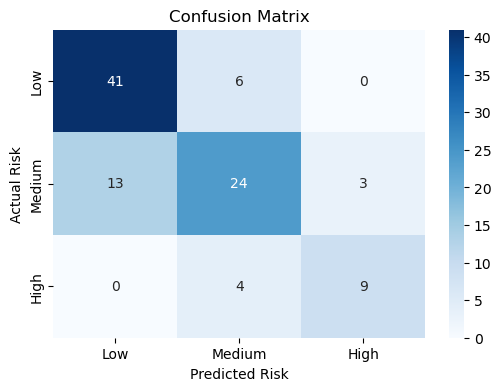

In [15]:
# 3. Model Training
# Train a Decision Tree classifier for simplicity.
clf = DecisionTreeClassifier(random_state=42)
clf.fit(X_train_scaled, y_train)

# Evaluate the model
y_pred = clf.predict(X_test_scaled)
accuracy = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {accuracy:.4f}")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Low', 'Medium', 'High']))

# Optionally, plot a confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=['Low', 'Medium', 'High'],
            yticklabels=['Low', 'Medium', 'High'])
plt.xlabel("Predicted Risk")
plt.ylabel("Actual Risk")
plt.title("Confusion Matrix")
plt.show()


In [16]:
# 4. Insurance Plan Recommendation
# Define insurance plan mapping based on risk category
insurance_plans = {
    0: "Basic Cyber Insurance",
    1: "Standard Cyber Insurance",
    2: "Premium Cyber Insurance"
}

# For a new input data point, predict the risk category and recommend an insurance plan.
# Example new input (tuple of 5 features)
new_input = (3, 7.5, 6, 80, 70)  # sample values
new_input_np = np.asarray(new_input).reshape(1, -1)
new_input_scaled = scaler.transform(new_input_np)

predicted_risk_label = clf.predict(new_input_scaled)[0]
recommended_plan = insurance_plans[predicted_risk_label]

print(f"Predicted Risk Label: {predicted_risk_label}")
print(f"Recommended Insurance Plan: {recommended_plan}")


Predicted Risk Label: 1
Recommended Insurance Plan: Standard Cyber Insurance


C:\anaconda\lib\site-packages\sklearn\base.py:420: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [18]:
# 5. Save the Model for Deployment
# ------------------------------
from sklearn.pipeline import Pipeline
pipeline = Pipeline([
    ('scaler', scaler),
    ('clf', clf)
])
joblib.dump(pipeline, 'cyber_insurance_model.pkl')
print("Model saved as 'cyber_insurance_model.pkl'")

Model saved as 'cyber_insurance_model.pkl'
